# Importing libraries and reading data

In [1904]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder, RobustScaler
from sklearn.metrics  import silhouette_score
import joblib


In [1805]:
sns.set_theme(style='ticks', palette='colorblind', context='notebook')

In [1806]:
df= pd.read_csv(r"C:\Users\MINE\Desktop\Customer Segmentation\customer_segmentation.csv")

# Data inspection and Cleaning

In [1807]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [1808]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response'],
      dtype='object')

In [1809]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [1810]:
df.nunique()

ID                     2240
Year_Birth               59
Education                 5
Marital_Status            8
Income                 1974
Kidhome                   3
Teenhome                  3
Dt_Customer             663
Recency                 100
MntWines                776
MntFruits               158
MntMeatProducts         558
MntFishProducts         182
MntSweetProducts        177
MntGoldProds            213
NumDealsPurchases        15
NumWebPurchases          15
NumCatalogPurchases      14
NumStorePurchases        14
NumWebVisitsMonth        16
AcceptedCmp3              2
AcceptedCmp4              2
AcceptedCmp5              2
AcceptedCmp1              2
AcceptedCmp2              2
Complain                  2
Z_CostContact             1
Z_Revenue                 1
Response                  2
dtype: int64

In [1811]:
today= dt.datetime.now().date()
df['age']= today.year - df['Year_Birth']

In [1812]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,age
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,0,0,0,0,0,0,3,11,1,69
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,0,0,0,0,0,0,3,11,0,72
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,0,0,0,0,0,0,3,11,0,61
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,0,0,0,0,0,0,3,11,0,42
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,0,0,0,0,0,0,3,11,0,45


In [1813]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
age                     0
dtype: int64

In [1814]:
df.dropna(inplace=True)

In [1815]:
df.duplicated().sum()

0

In [1816]:
df['Dt_Customer']= pd.to_datetime(df['Dt_Customer'], dayfirst=True)

In [1817]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,age
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,0,0,0,0,0,0,3,11,1,69
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,0,0,0,0,0,0,3,11,0,72
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,0,0,0,0,0,0,3,11,0,61
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,0,0,0,0,0,0,3,11,0,42
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,0,0,0,0,0,0,3,11,0,45


In [1818]:
df['Children']= df['Kidhome'] + df['Teenhome']
df['amount_spent']= df['MntFishProducts'] + df['MntFruits'] + df['MntGoldProds']+ df['MntSweetProducts'] + df['MntWines'] + df['MntMeatProducts']
df['campaign']= df['AcceptedCmp1'] + df['AcceptedCmp2'] + df['AcceptedCmp3']+ df['AcceptedCmp4'] + df['AcceptedCmp5']


In [1819]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,age,Children,amount_spent,campaign
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,0,0,0,3,11,1,69,0,1617,0
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,0,0,0,3,11,0,72,2,27,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,0,0,0,3,11,0,61,0,776,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,0,0,0,3,11,0,42,1,53,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,0,0,0,3,11,0,45,1,422,0


In [1820]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response',
       'age', 'Children', 'amount_spent', 'campaign'],
      dtype='object')

In [1821]:
df.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,...,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,age,Children,amount_spent,campaign
count,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216,2216.000000,2216.000000,2216.000000,2216.000000,...,2216.000000,2216.000000,2216.000000,2216.0,2216.0,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000
mean,5588.353339,1968.820397,52247.251354,0.441787,0.505415,2013-07-10 11:29:27.509025280,49.012635,305.091606,26.356047,166.995939,...,0.064079,0.013538,0.009477,3.0,11.0,0.150271,57.179603,0.947202,607.075361,0.298285
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,2012-07-30 00:00:00,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,3.0,11.0,0.000000,30.000000,0.000000,5.000000,0.000000
25%,2814.750000,1959.000000,35303.000000,0.000000,0.000000,2013-01-16 00:00:00,24.000000,24.000000,2.000000,16.000000,...,0.000000,0.000000,0.000000,3.0,11.0,0.000000,49.000000,0.000000,69.000000,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,2013-07-08 12:00:00,49.000000,174.500000,8.000000,68.000000,...,0.000000,0.000000,0.000000,3.0,11.0,0.000000,56.000000,1.000000,396.500000,0.000000
75%,8421.750000,1977.000000,68522.000000,1.000000,1.000000,2013-12-31 00:00:00,74.000000,505.000000,33.000000,232.250000,...,0.000000,0.000000,0.000000,3.0,11.0,0.000000,67.000000,1.000000,1048.000000,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,2014-06-29 00:00:00,99.000000,1493.000000,199.000000,1725.000000,...,1.000000,1.000000,1.000000,3.0,11.0,1.000000,133.000000,3.000000,2525.000000,4.000000
std,3249.376275,11.985554,25173.076661,0.536896,0.544181,NaN,28.948352,337.327920,39.793917,224.283273,...,0.244950,0.115588,0.096907,0.0,0.0,0.357417,11.985554,0.749062,602.900476,0.679209


# EDA and Data visualization

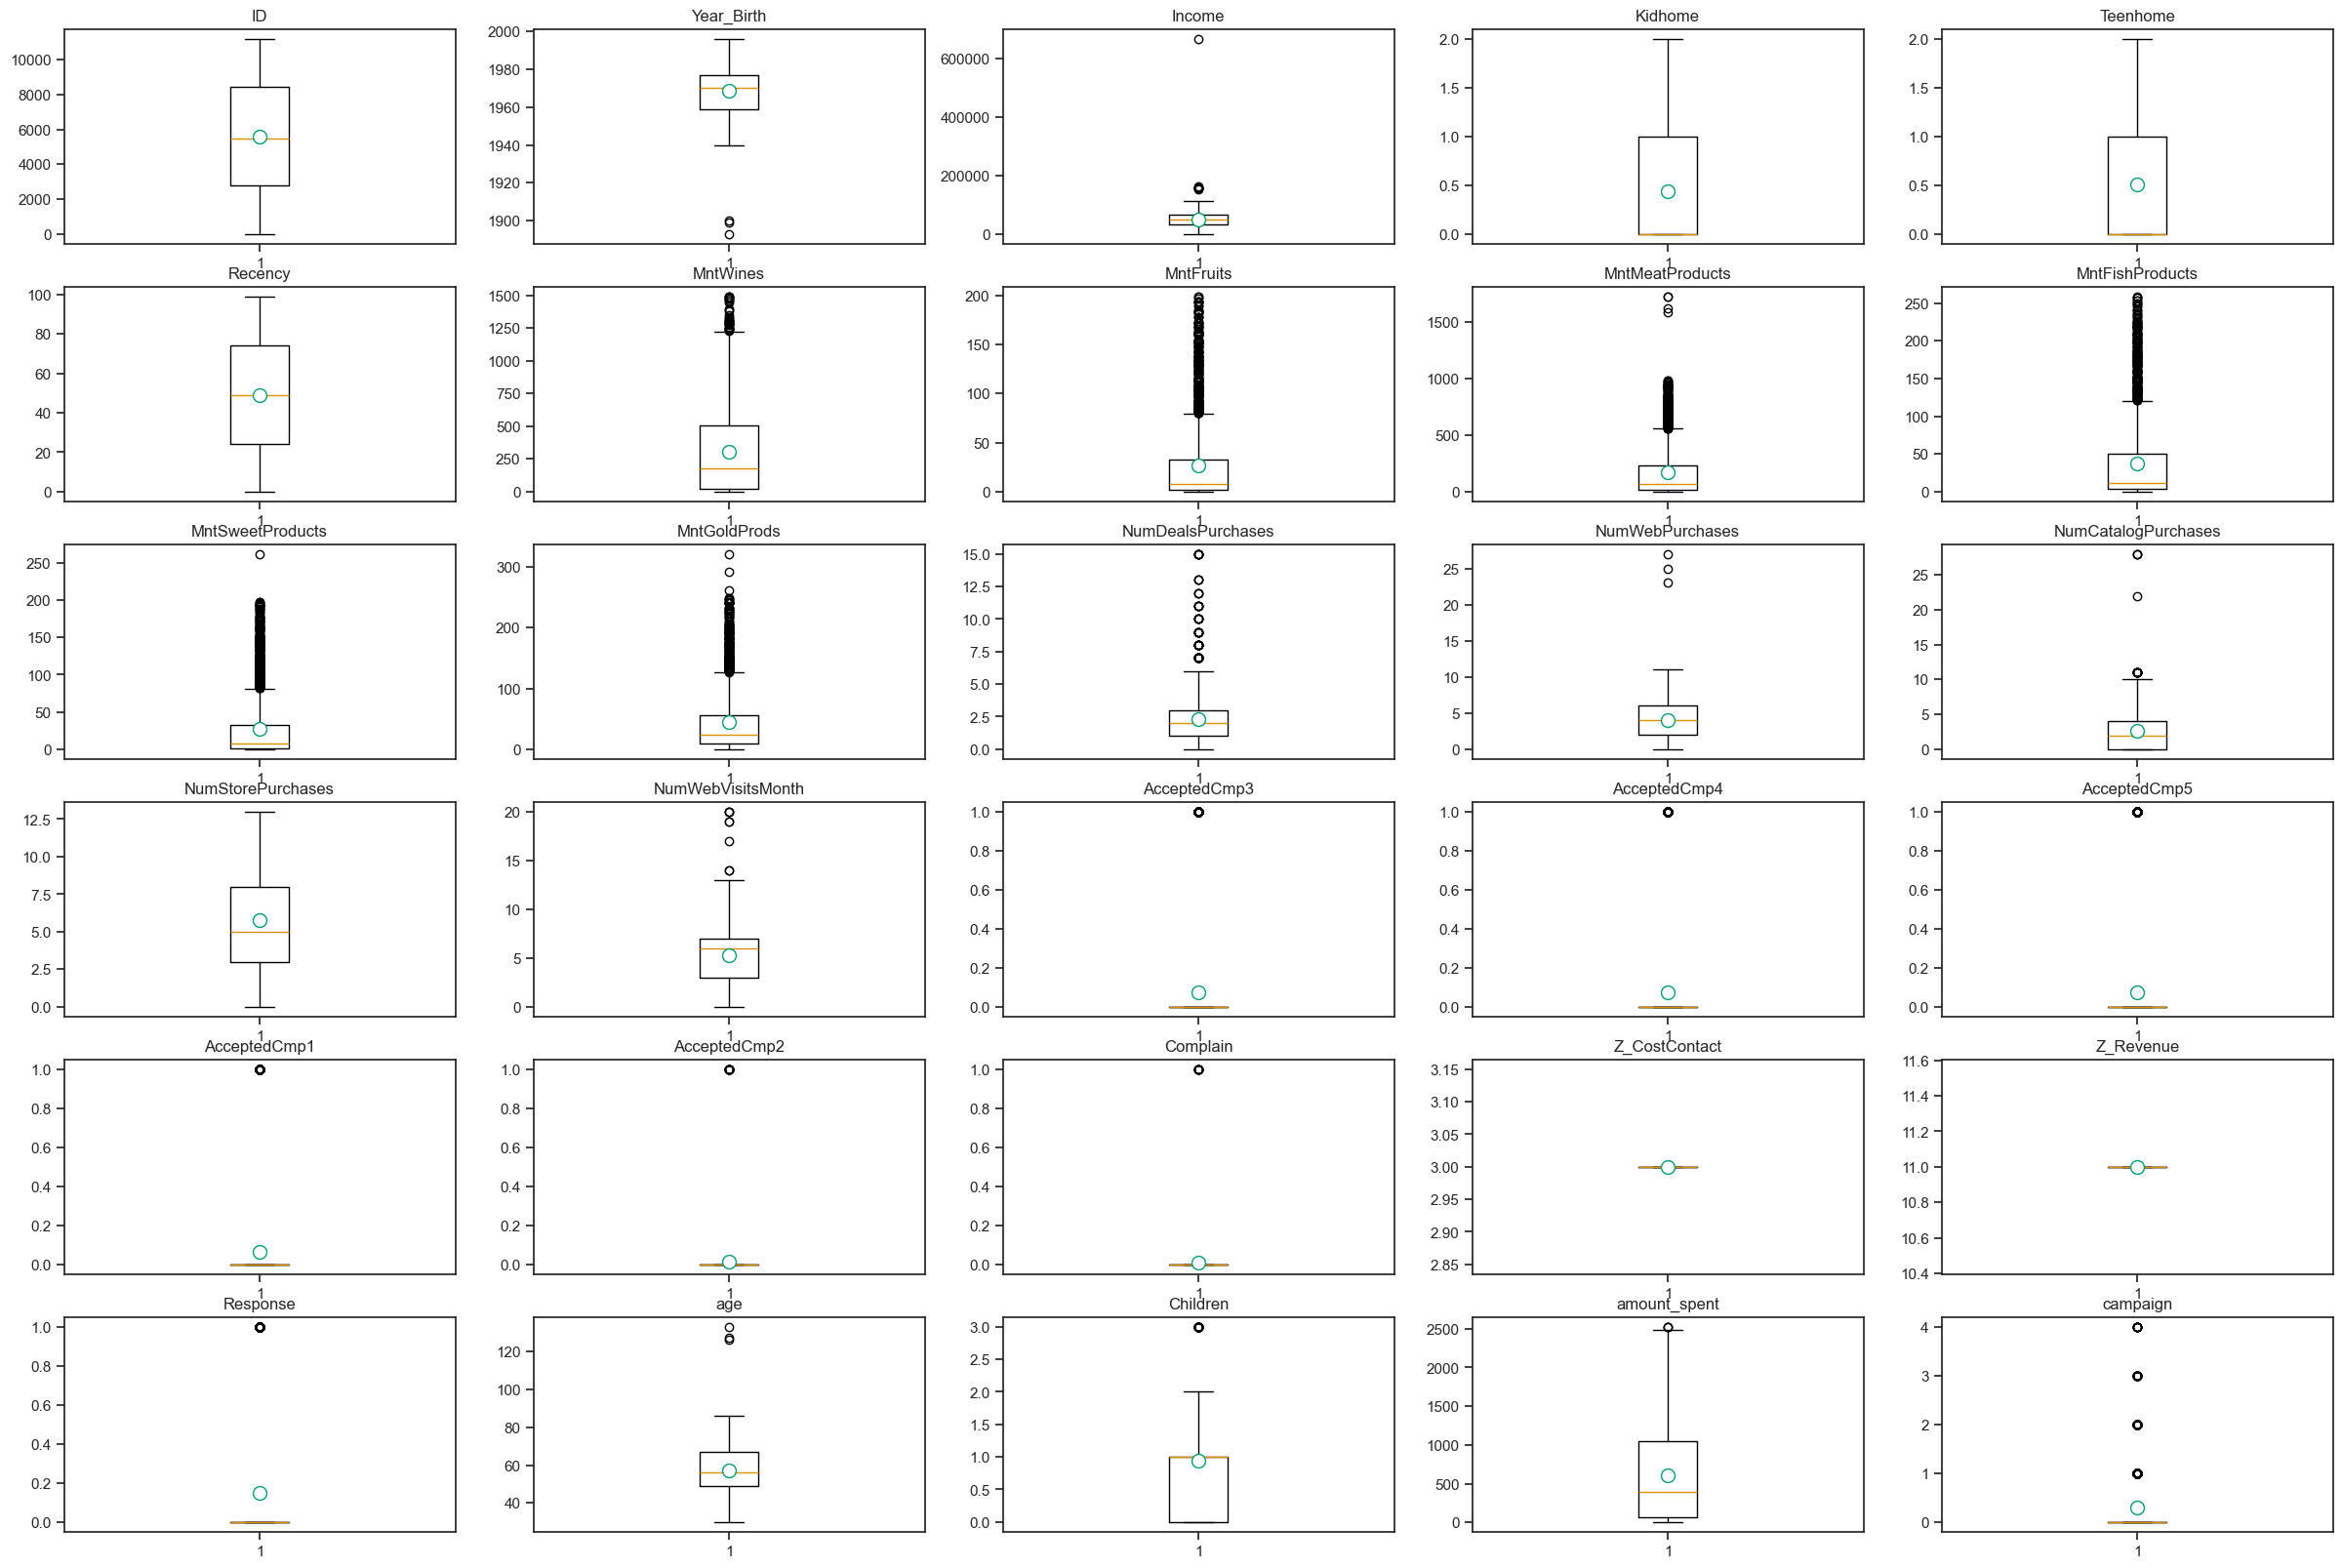

In [1822]:

fig,axes= plt.subplots(ncols=5,nrows=6, figsize= (30,20))
axes= axes.reshape(-1)
for i,col in enumerate(df.select_dtypes(include=np.number)):
    axes[i].boxplot(df[col],showmeans= True,
                meanprops= {
                    "marker": "o",
                    "markerfacecolor": "White",
                    "markersize": "10"
                },)
    axes[i].set_title(col)

plt.show()
    

In [1823]:
# Fixing outliers

def outlier(col, df):
  Q1= df[col].quantile(0.25)
  Q3= df[col].quantile(0.71)
  IQR= Q3 - Q1
  upper_limit= Q3 + 1.5 * IQR
  lower_limit= Q1- 1.5 * IQR
  df[col]= df[col].where((df[col] <= upper_limit ) & (df[col]>= lower_limit), IQR)

In [1824]:
outlier('Income', df)

In [1825]:
outlier('age', df)

In [1826]:
df= df[df['age']> df['age'].min()]

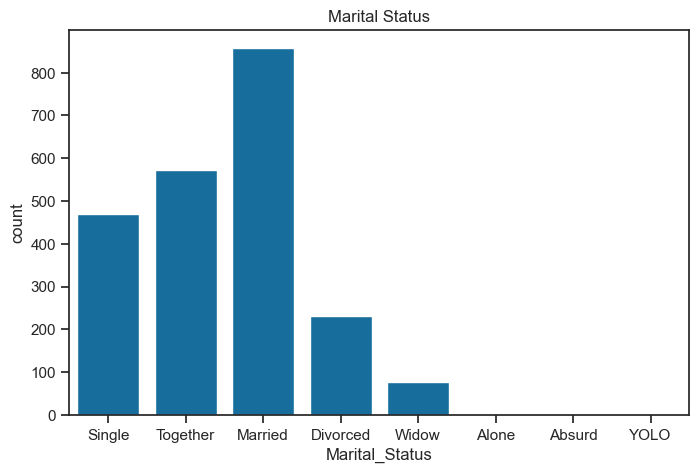

In [1827]:
plt.figure(figsize=(8,5))
sns.countplot(data= df, x= 'Marital_Status')


plt.title('Marital Status')
plt.show()

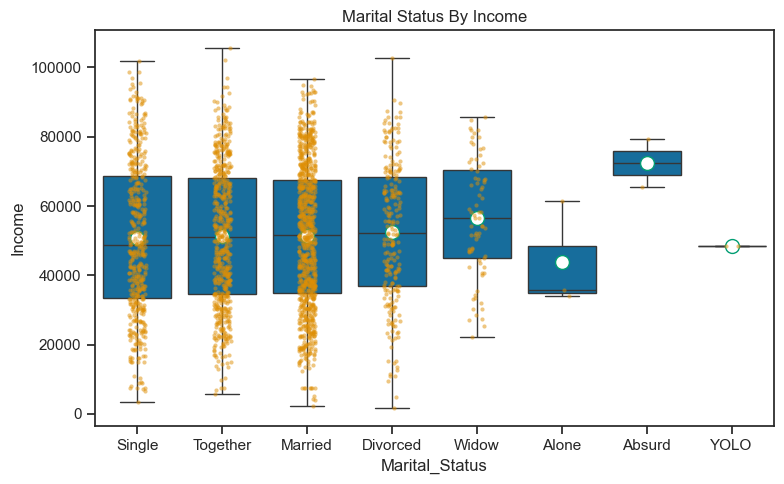

In [1828]:
plt.figure(figsize=(8,5))

sns.boxplot(x='Marital_Status', y='Income', data=df,showmeans= True,
                meanprops= {
                    "marker": "o",
                    "markerfacecolor": "White",
                    "markersize": "10"
                },)
sns.stripplot(x='Marital_Status', y='Income', data=df,alpha=0.5,size=3,jitter=True)

plt.title('Marital Status By Income')
plt.tight_layout()
plt.show()

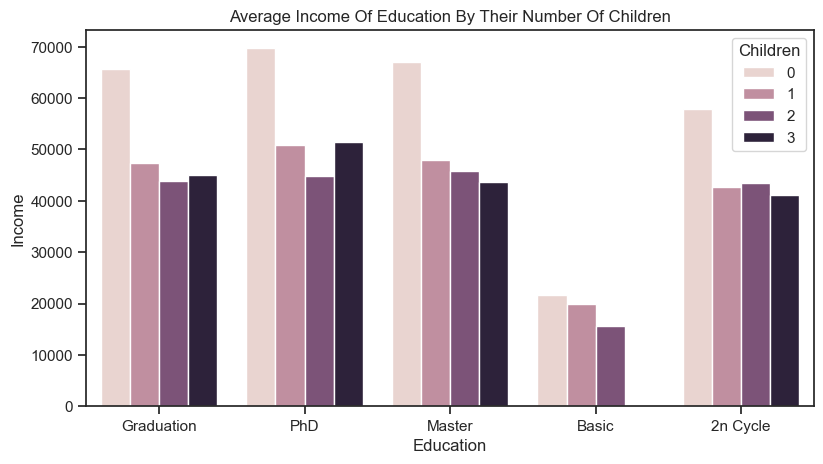

In [1829]:
plt.figure(figsize=(8.4,4.6))

sns.barplot(data= df, x='Education', y='Income', estimator='mean', hue='Children',errorbar=None)

plt.tight_layout()
plt.title('Average Income Of Education By Their Number Of Children')
plt.show()

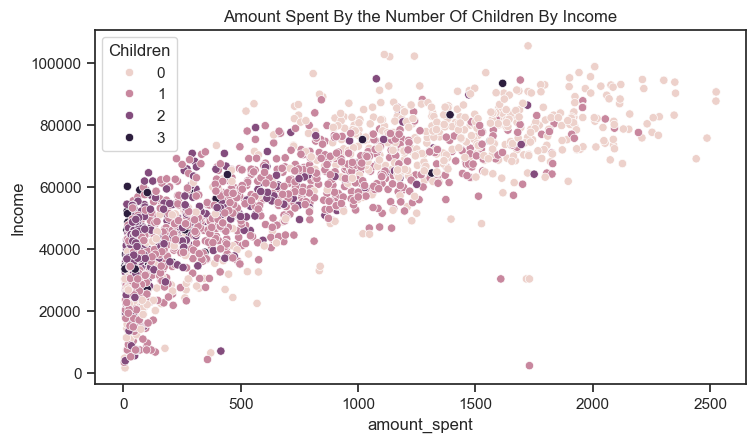

In [1831]:
plt.figure(figsize=(8.4,4.6))

sns.scatterplot(data=df, y='Income', x='amount_spent', hue= 'Children',)
plt.title('Amount Spent By the Number Of Children By Income')

plt.show()

In [1832]:
df.Income.describe()

count      2213.000000
mean      51507.673520
std       20677.442707
min        1730.000000
25%       34935.000000
50%       51141.000000
75%       68142.000000
max      105471.000000
Name: Income, dtype: float64

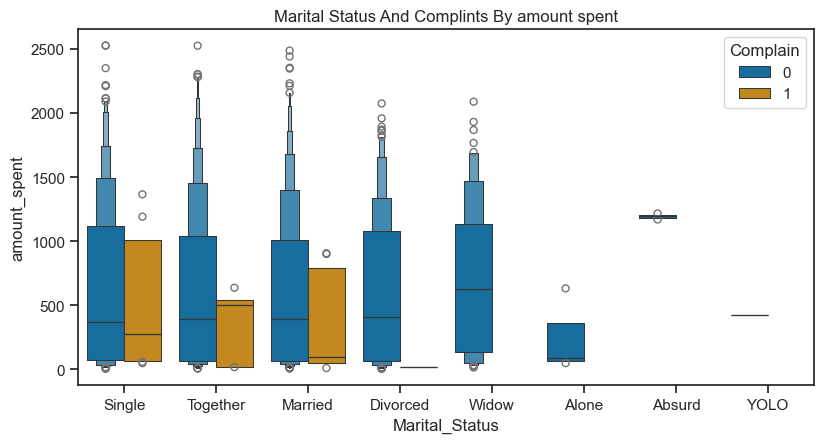

In [1833]:
plt.figure(figsize=(8.4,4.6))

sns.boxenplot(data=df, x='Marital_Status', y='amount_spent', hue='Complain')

plt.title('Marital Status And Complints By amount spent')
plt.tight_layout()
plt.show()

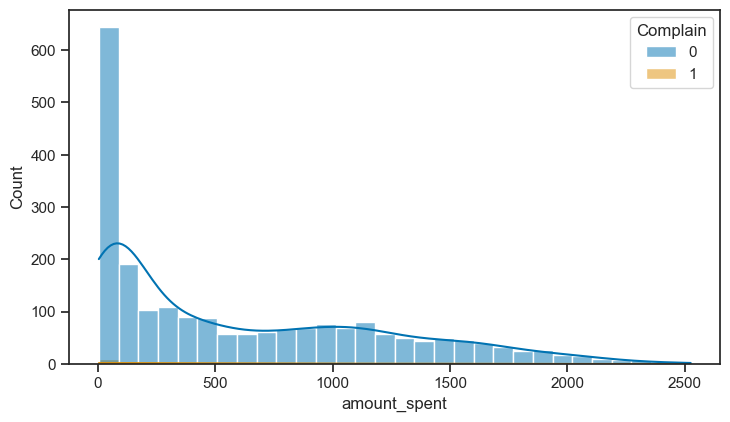

In [1834]:
plt.figure(figsize=(8.4,4.6))

sns.histplot(data= df, hue= 'Complain', x='amount_spent', bins=30, kde= True)

plt.show()

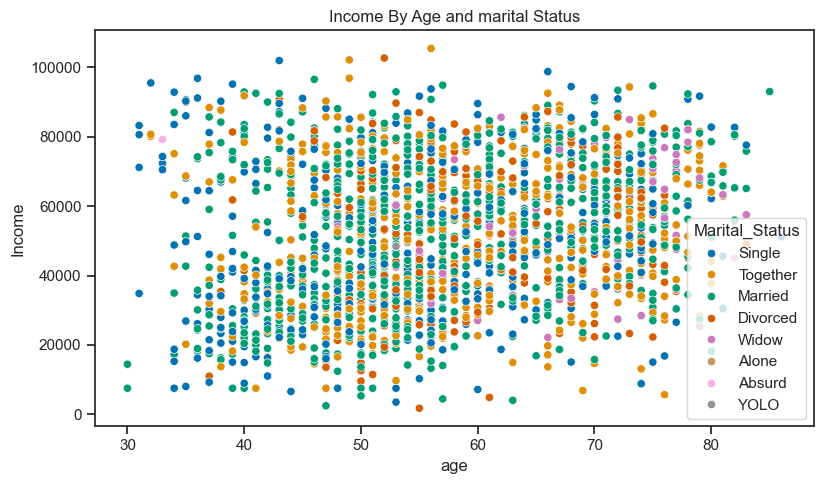

In [1835]:
plt.figure(figsize=(8.4,5))

sns.scatterplot(data=df, x='age', y= 'Income', hue='Marital_Status')


plt.title('Income By Age and marital Status')
plt.tight_layout()
plt.show()

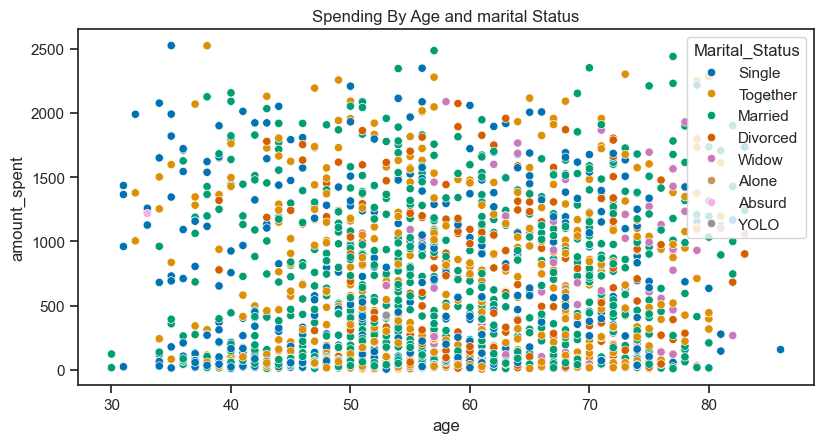

In [1836]:
plt.figure(figsize=(8.4,4.6))


sns.scatterplot(data=df, x='age', y= 'amount_spent', hue='Marital_Status')
plt.title('Spending By Age and marital Status')
plt.tight_layout()
plt.show()

In [1837]:
df[ 'Year_Birth'].value_counts().head()

Year_Birth
1976    89
1971    86
1975    83
1972    78
1978    76
Name: count, dtype: int64

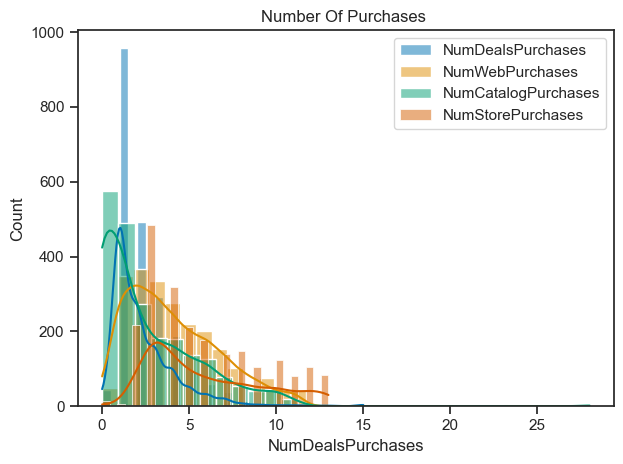

In [1838]:
col= ['NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases','NumStorePurchases',]
for i,col in enumerate(col):
  sns.histplot(data=df, x=df[col], bins=30, kde=True, label=col)
  plt.title("Number Of Purchases ")
plt.legend()
plt.tight_layout()
plt.show()

In [1839]:
df.groupby('NumWebPurchases')['NumWebVisitsMonth'].agg(['mean','sum', 'count']).reset_index().head()

,NumWebPurchases,mean,sum,count
0,0,5.979167,287,48
1,1,6.239193,2165,347
2,2,5.716621,2098,367
3,3,5.131737,1714,334
4,4,4.115942,1136,276


In [1840]:
df.Complain.value_counts()

Complain
0    2193
1      20
Name: count, dtype: int64

In [1841]:
age_by_complain=df[df['Complain']== 1]
age_by_complain=age_by_complain[['age','Complain']].value_counts().reset_index().sort_values('count', ascending=False)
age_by_complain.head()

,age,Complain,count
0,67,1,3
1,48,1,2
2,72,1,2
3,31,1,1
4,38,1,1


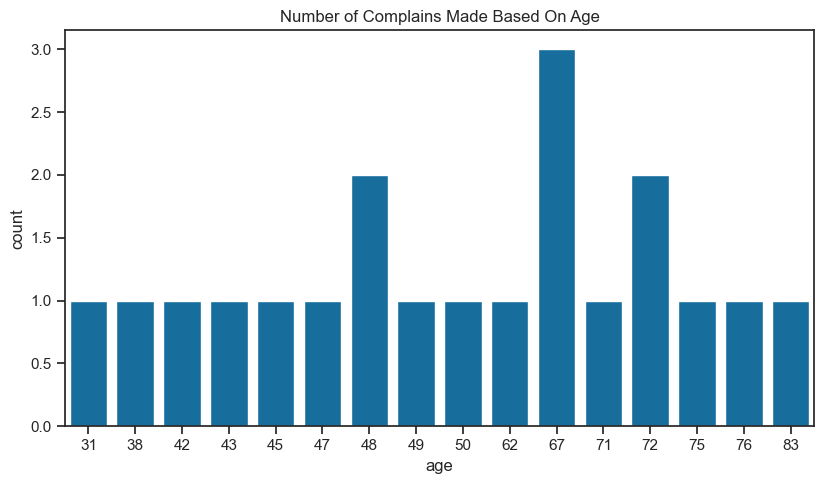

In [1842]:
plt.figure(figsize=(8.4,5))

sns.barplot(data=age_by_complain, x='age', y='count')


plt.title('Number of Complains Made Based On Age')
plt.tight_layout()
plt.show()

In [1843]:
df.groupby('Children')['amount_spent'].agg(['mean','sum','count'])

,mean,sum,count
Children,,,
0,1104.064873,697769,632
1,475.473543,530153,1115
2,246.735577,102642,416
3,255.500000,12775,50


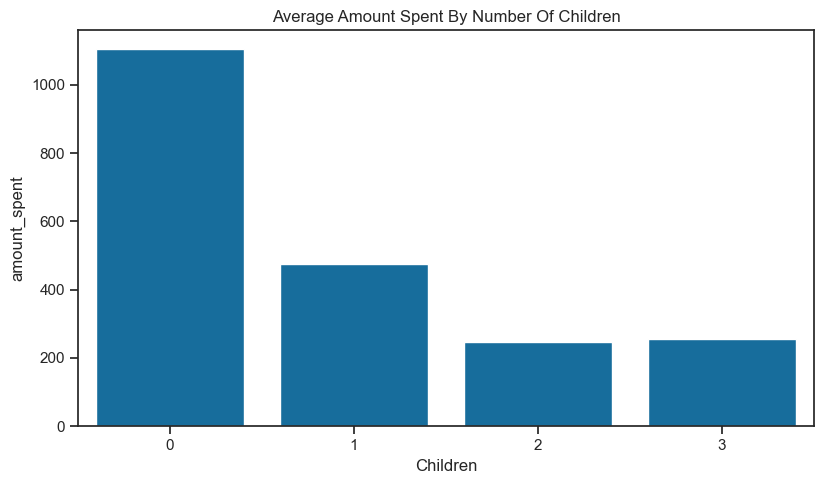

In [1844]:
plt.figure(figsize=(8.4,5))

sns.barplot(data=df, y='amount_spent', x= 'Children', estimator='mean', errorbar=None)


plt.title('Average Amount Spent By Number Of Children')
plt.tight_layout()
plt.show()

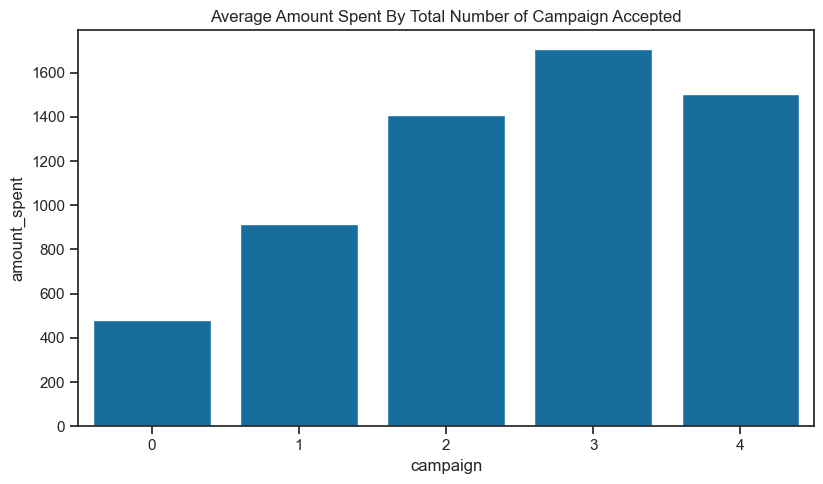

In [1845]:
plt.figure(figsize=(8.4,5))

sns.barplot(data=df, y='amount_spent', x= 'campaign', estimator='mean', errorbar=None)


plt.title('Average Amount Spent By Total Number of Campaign Accepted')
plt.tight_layout()
plt.show()

In [1846]:
df.groupby('Education')['amount_spent'].agg(['mean', 'count', 'sum']).reset_index()

,Education,mean,count,sum
0,2n Cycle,499.489899,198,98899
1,Basic,81.796296,54,4417
2,Graduation,621.686380,1116,693802
3,Master,609.767123,365,222565
4,PhD,674.283333,480,323656


In [1847]:
df.groupby('Education')['Income'].agg(['mean', 'count', 'sum']).reset_index()

,Education,mean,count,sum
0,2n Cycle,47625.333333,198,9429816.0
1,Basic,20306.259259,54,1096538.0
2,Graduation,51925.955645,1116,57949366.5
3,Master,52568.645205,365,19187555.5
4,PhD,54840.011458,480,26323205.5


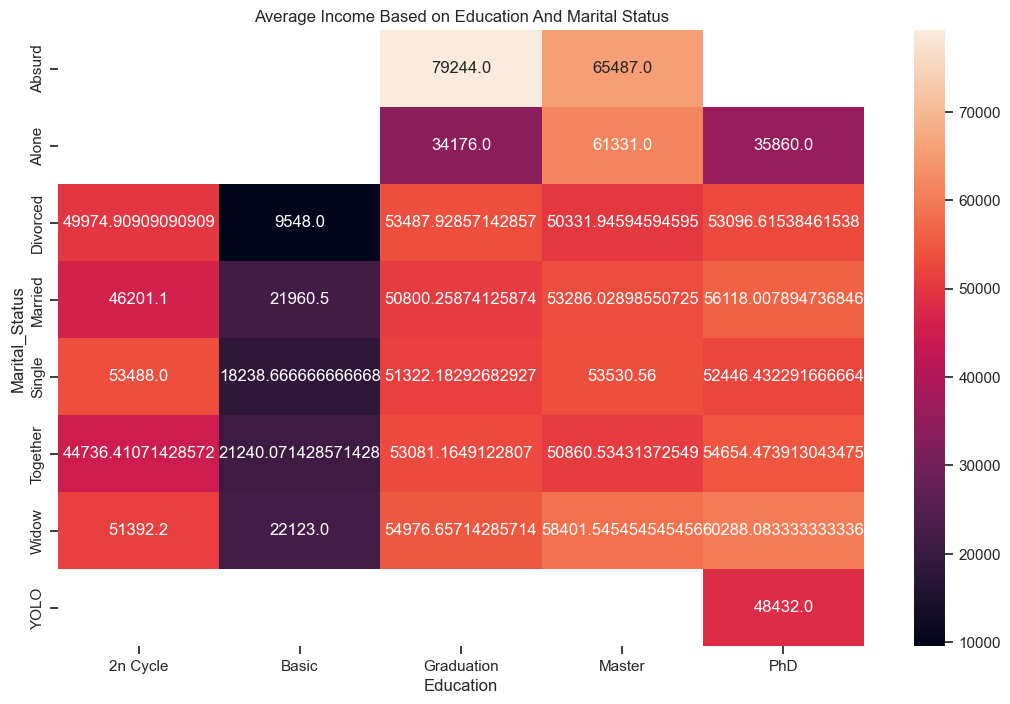

In [1848]:
income=df.pivot_table(values='Income',columns='Education',index='Marital_Status', aggfunc='mean')
plt.figure(figsize=(13,8))
sns.heatmap(income, annot=True, fmt='')
plt.title("Average Income Based on Education And Marital Status")
plt.show()

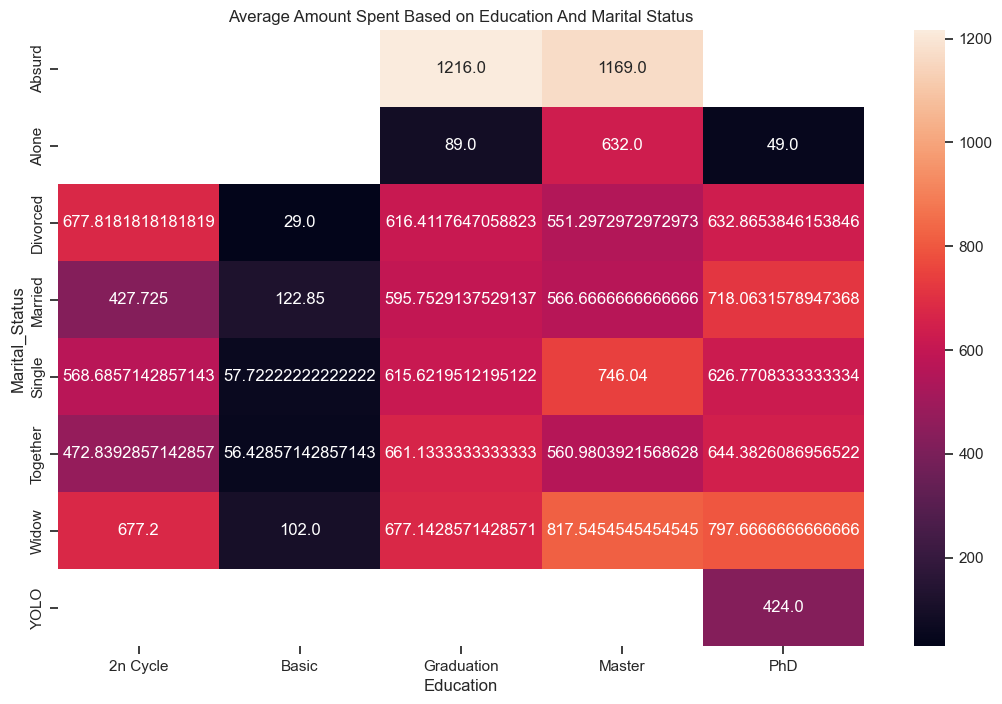

In [1849]:
amount_spent=df.pivot_table(values='amount_spent',columns='Education',index='Marital_Status', aggfunc='mean')
plt.figure(figsize=(13,8))
sns.heatmap(amount_spent, annot=True, fmt='')
plt.title("Average Amount Spent Based on Education And Marital Status")
plt.show()

In [1850]:
df.groupby('Education')[['NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases','NumStorePurchases']].agg(['mean', 'count', 'sum'])

NumDealsPurchases             NumWebPurchases              \
                        mean count   sum            mean count   sum   
Education                                                              
2n Cycle            2.272727   198   450        3.787879   198   750   
Basic               1.796296    54    97        1.888889    54   102   
Graduation          2.311828  1116  2580        4.115591  1116  4593   
Master              2.424658   365   885        4.035616   365  1473   
PhD                 2.362500   480  1134        4.433333   480  2128   

           NumCatalogPurchases             NumStorePurchases              
                          mean count   sum              mean count   sum  
Education                                                                 
2n Cycle              2.373737   198   470          5.595960   198  1108  
Basic                 0.481481    54    26          2.851852    54   154  
Graduation            2.738351  1116  3056          5.841398  1116  6519  
Master                2.545205   365   929          5.887671   365  2149  
PhD                   2.981250   480  1431          6.077083   480  2917

In [1851]:
df['purchases']= df.NumCatalogPurchases + df.NumDealsPurchases + df.NumStorePurchases + df.NumWebPurchases

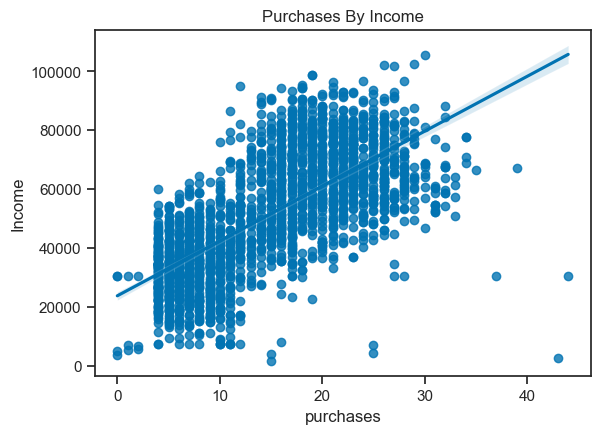

In [1852]:
plt.figure(figsize=(6.4,4.5))

sns.regplot(data=df, x='purchases', y='Income')

plt.title('Purchases By Income')
plt.show()

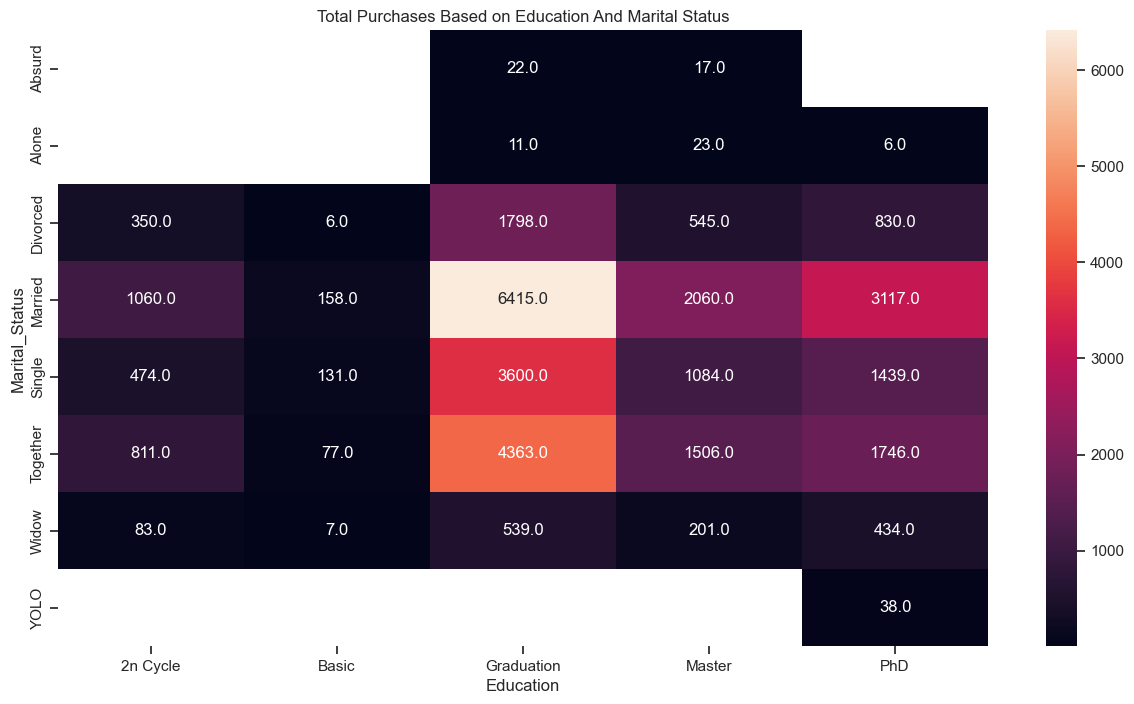

In [1853]:
amount_spent=df.pivot_table(values='purchases',columns='Education',index='Marital_Status', aggfunc='sum')
plt.figure(figsize=(15,8))
sns.heatmap(amount_spent, annot=True, fmt='')
plt.title("Total Purchases Based on Education And Marital Status")
plt.show()

In [1854]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response',
       'age', 'Children', 'amount_spent', 'campaign', 'purchases'],
      dtype='object')

In [1855]:
df=df[['age','Education', 'Marital_Status', 'Income','amount_spent','purchases','NumWebVisitsMonth','campaign']]

In [1856]:
df.head()

,age,Education,Marital_Status,Income,amount_spent,purchases,NumWebVisitsMonth,campaign
0,69,Graduation,Single,58138.0,1617,25,7,0
1,72,Graduation,Single,46344.0,27,6,5,0
2,61,Graduation,Together,71613.0,776,21,4,0
3,42,Graduation,Together,26646.0,53,8,6,0
4,45,PhD,Married,58293.0,422,19,5,0


In [1857]:
df.describe()

,age,Income,amount_spent,purchases,NumWebVisitsMonth,campaign
count,2213.000000,2213.000000,2213.000000,2213.000000,2213.000000,2213.000000
mean,57.082693,51507.673520,607.021690,14.889742,5.321735,0.298238
std,11.700216,20677.442707,602.488663,7.670341,2.425092,0.679446
min,30.000000,1730.000000,5.000000,0.000000,0.000000,0.000000
25%,49.000000,34935.000000,69.000000,8.000000,3.000000,0.000000
50%,56.000000,51141.000000,397.000000,15.000000,6.000000,0.000000
75%,67.000000,68142.000000,1048.000000,21.000000,7.000000,0.000000
max,86.000000,105471.000000,2525.000000,44.000000,20.000000,4.000000


In [1858]:
corr= df.select_dtypes(include=np.number).corr()

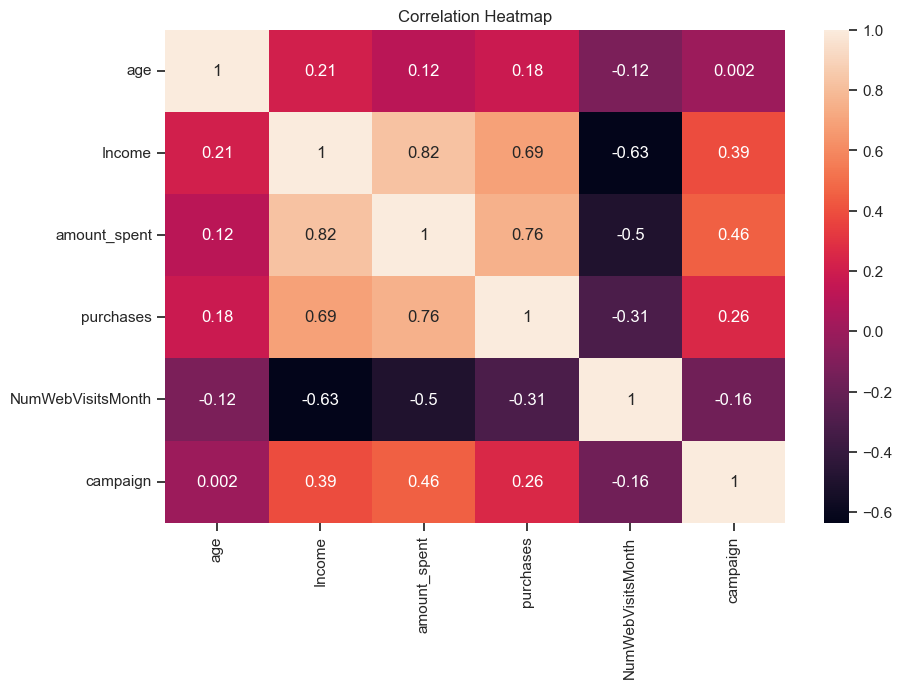

In [1859]:
plt.figure(figsize=(10,6.4))


sns.heatmap(corr, annot=True)
plt.title('Correlation Heatmap')
plt.show()

# Preprocessing

In [1860]:
df1= df.copy()
df1.head()

,age,Education,Marital_Status,Income,amount_spent,purchases,NumWebVisitsMonth,campaign
0,69,Graduation,Single,58138.0,1617,25,7,0
1,72,Graduation,Single,46344.0,27,6,5,0
2,61,Graduation,Together,71613.0,776,21,4,0
3,42,Graduation,Together,26646.0,53,8,6,0
4,45,PhD,Married,58293.0,422,19,5,0


In [1861]:
lb= LabelEncoder()
for col in df1.select_dtypes(include='object').columns:
  df1[col]= lb.fit_transform(df1[col])

In [1862]:
df1.head()

,age,Education,Marital_Status,Income,amount_spent,purchases,NumWebVisitsMonth,campaign
0,69,2,4,58138.0,1617,25,7,0
1,72,2,4,46344.0,27,6,5,0
2,61,2,5,71613.0,776,21,4,0
3,42,2,5,26646.0,53,8,6,0
4,45,4,3,58293.0,422,19,5,0


In [1863]:
df1.isnull().sum()

age                  0
Education            0
Marital_Status       0
Income               0
amount_spent         0
purchases            0
NumWebVisitsMonth    0
campaign             0
dtype: int64

In [1864]:
df1.dropna(inplace=True)

In [1865]:
# Scaling

scale= RobustScaler()
x= scale.fit_transform(df1)

In [1866]:
x

array([[ 0.72222222,  0.        ,  0.        , ...,  0.76923077,
         0.25      ,  0.        ],
       [ 0.88888889,  0.        ,  0.        , ..., -0.69230769,
        -0.25      ,  0.        ],
       [ 0.27777778,  0.        ,  0.5       , ...,  0.46153846,
        -0.5       ,  0.        ],
       ...,
       [-0.61111111,  0.        , -1.        , ...,  0.30769231,
         0.        ,  1.        ],
       [ 0.77777778,  1.        ,  0.5       , ...,  0.61538462,
        -0.75      ,  0.        ],
       [ 0.88888889,  2.        , -0.5       , ..., -0.30769231,
         0.25      ,  0.        ]])

In [1867]:
pca= PCA(n_components=2)
x_pca= pca.fit_transform(x)

In [1868]:
scores= []
inertia= []

for i in range(2,11):
  model= KMeans(n_clusters=i, n_init=10, max_iter=300, init='k-means++', random_state= 42)
  labels = model.fit_predict(x)
  score=silhouette_score(x,labels)
  scores.append(score)
  inertia.append(model.inertia_)

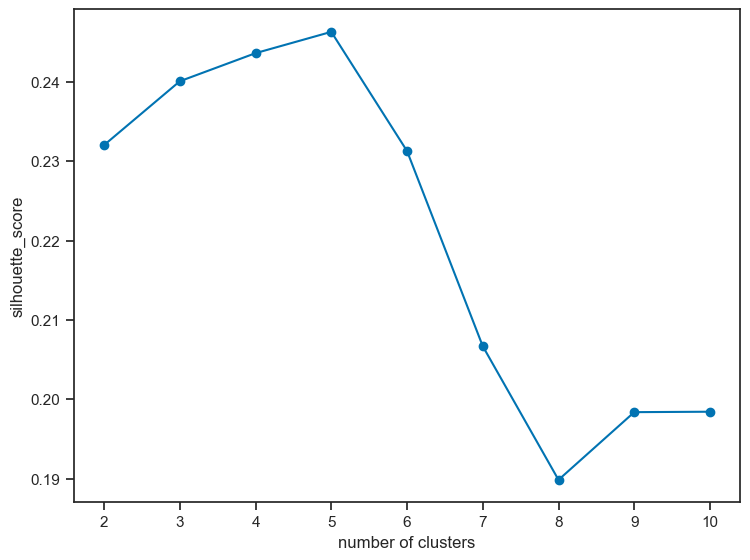

In [1869]:
plt.figure(figsize=(8.6,6.4))
plt.plot(list(range(2,11)),scores, marker= 'o')

plt.xlabel('number of clusters')
plt.ylabel('silhouette_score')
plt.show()

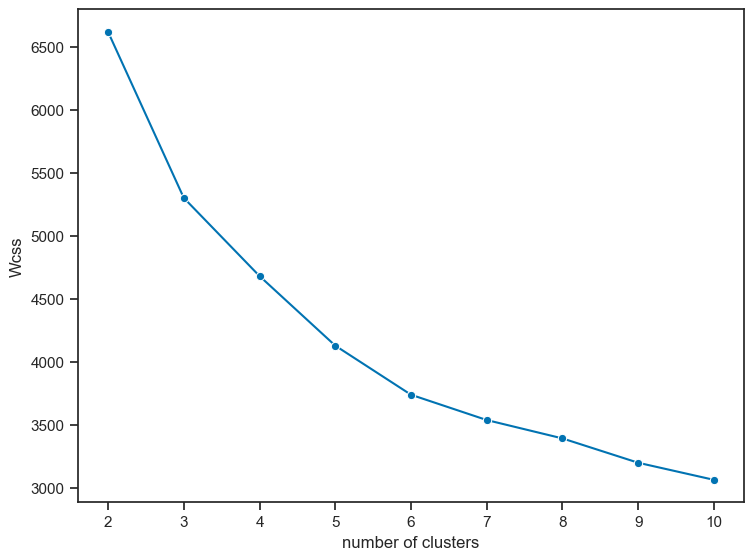

In [1870]:
plt.figure(figsize=(8.6,6.4))
sns.lineplot(x=list(range(2,11)), y= inertia, marker='o')


plt.xlabel('number of clusters')
plt.ylabel('Wcss')
plt.show()
plt.show()

In [1871]:
final_model= KMeans(n_clusters=5, max_iter=100, n_init=10, random_state=42, init='k-means++')

In [1872]:
df['Cluster']= final_model.fit_predict(x)

In [1873]:
df['Cluster'].value_counts()

Cluster
3    741
1    575
2    550
0    193
4    154
Name: count, dtype: int64

In [1874]:
df['x'], df['y']= x_pca[:,0],x_pca[:,1]

In [1875]:
df.head()

,age,Education,Marital_Status,Income,amount_spent,purchases,NumWebVisitsMonth,campaign,Cluster,x,y
0,69,Graduation,Single,58138.0,1617,25,7,0,1,0.251957,-0.811668
1,72,Graduation,Single,46344.0,27,6,5,0,3,-0.608686,0.354178
2,61,Graduation,Together,71613.0,776,21,4,0,1,0.121010,-0.735428
3,42,Graduation,Together,26646.0,53,8,6,0,3,-1.107736,0.635589
4,45,PhD,Married,58293.0,422,19,5,0,2,1.187879,0.932999


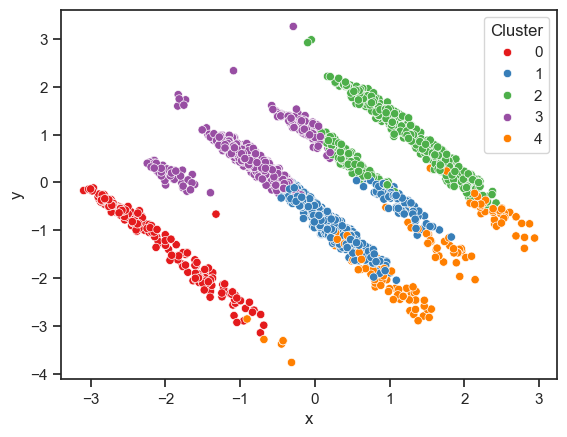

In [1876]:
plt.Figure(figsize=(6.4,4.6))

sns.scatterplot(x='x', y='y', data=df, hue='Cluster', palette='Set1')

plt.show()

In [1877]:
features= df.drop(columns=['Cluster', 'Education', 'Marital_Status']).columns
cluster_features= df.groupby('Cluster')[features].mean()

In [1878]:
round(cluster_features, 2)

,age,Income,amount_spent,purchases,NumWebVisitsMonth,campaign,x,y
Cluster,,,,,,,,
0,53.01,46452.93,464.81,13.79,5.55,0.18,-2.07,-1.23
1,59.55,68058.45,1060.86,21.16,3.84,0.22,0.32,-0.80
2,60.83,52385.21,551.88,15.59,5.50,0.16,1.11,0.88
3,53.54,33162.81,120.11,8.54,6.70,0.09,-0.83,0.60
4,56.65,81181.47,1630.53,20.89,3.35,2.26,1.45,-1.50


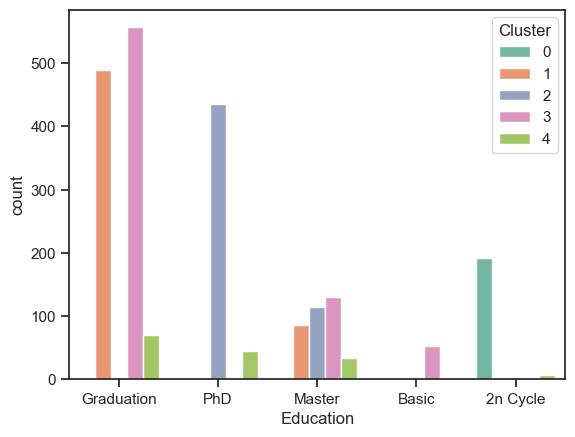

In [1898]:
sns.countplot(data=df, x='Education', hue='Cluster', palette='Set2')

plt.show()

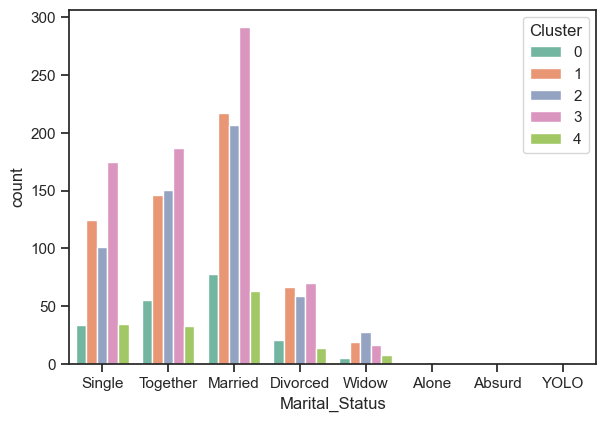

In [1880]:
plt.figure(figsize=(6.8,4.6))
sns.countplot(data=df, x='Marital_Status', hue='Cluster',palette='Set2')

plt.show()

In [1896]:
df[['Cluster','Marital_Status','Education']].value_counts().unstack(-1)

Education               2n Cycle  Basic  Graduation  Master    PhD
Cluster Marital_Status                                            
0       Divorced            21.0    NaN         NaN     NaN    NaN
        Married             77.0    1.0         NaN     NaN    NaN
        Single              34.0    NaN         NaN     NaN    NaN
        Together            55.0    NaN         NaN     NaN    NaN
        Widow                5.0    NaN         NaN     NaN    NaN
1       Absurd               NaN    NaN         NaN     1.0    NaN
        Divorced             NaN    NaN        56.0    11.0    NaN
        Married              NaN    NaN       182.0    35.0    NaN
        Single               NaN    NaN       107.0    18.0    NaN
        Together             NaN    NaN       126.0    20.0    NaN
        Widow                NaN    NaN        18.0     1.0    NaN
2       Alone                NaN    NaN         NaN     1.0    1.0
        Divorced             NaN    NaN         NaN    11.0   48.0
        Married              NaN    NaN         NaN    41.0  166.0
        Single               NaN    NaN         NaN    12.0   89.0
        Together             NaN    NaN         NaN    43.0  108.0
        Widow                NaN    NaN         NaN     7.0   21.0
        YOLO                 NaN    NaN         NaN     NaN    2.0
3       Alone                NaN    NaN         1.0     NaN    NaN
        Divorced             NaN    1.0        55.0    14.0    NaN
        Married              NaN   19.0       221.0    52.0    NaN
        Single               NaN   18.0       124.0    33.0    NaN
        Together             NaN   14.0       141.0    31.0    1.0
        Widow                NaN    1.0        15.0     NaN    NaN
4       Absurd               NaN    NaN         1.0     NaN    NaN
        Divorced             1.0    NaN         8.0     1.0    4.0
        Married              3.0    NaN        26.0    10.0   24.0
        Single               1.0    NaN        15.0    12.0    7.0
        Together             1.0    NaN        18.0     8.0    6.0
        Widow                NaN    NaN         2.0     3.0    3.0

> INSIGHT

* Cluster 4 are the highest earners and spenders, they also receive the highest campaign
* Clusrer 1 make the most purchases and are also the second top spenders, most of the members are graduation holders and are married.
* Cluster 3 visit the web the most, most are married and graduation holders.
* Cluster 2 has the highest amount of Phd Holders and Married Folks, they also rank as the oldest.
* Cluster 0 has the lower avarage age in the distribution, most are married with 2n Cycle education status.

In [1905]:
joblib.dump(final_model,r"C:\Users\MINE\Desktop\Customer Segmentation\model.pkl")

['C:\\Users\\MINE\\Desktop\\Customer Segmentation\\model.pkl']

In [1906]:
joblib.dump(scale,r"C:\Users\MINE\Desktop\Customer Segmentation\scale.pkl")

['C:\\Users\\MINE\\Desktop\\Customer Segmentation\\scale.pkl']

In [1907]:
joblib.dump(lb,r"C:\Users\MINE\Desktop\Customer Segmentation\encoder.pkl")

['C:\\Users\\MINE\\Desktop\\Customer Segmentation\\encoder.pkl']

In [1908]:
df.to_csv(r"C:\Users\MINE\Desktop\Customer Segmentation\clustered.csv")